# HCO và VNLS

Sau baseline, optimizer dùng model trong objective để chấm từng mask feature. Model vẫn là thành phần dự đoán; optimizer chỉ tìm bộ cột.

,method,seed,selected_count,average_precision_cv,objective_calls,wall_seconds
0,HCO,41,14,0.835524,6,15.587576
1,HCO,77,12,0.819636,6,12.747518
2,HCO,123,9,0.809266,6,12.876349
3,VNLS,41,9,0.827140,20,37.103642
4,VNLS,77,11,0.825199,18,29.898763
5,VNLS,123,9,0.822102,19,31.321165
6,HCO-VNLS,41,13,0.835236,14,29.609448
7,HCO-VNLS,77,10,0.814478,15,26.617622
8,HCO-VNLS,123,10,0.817211,15,30.628913


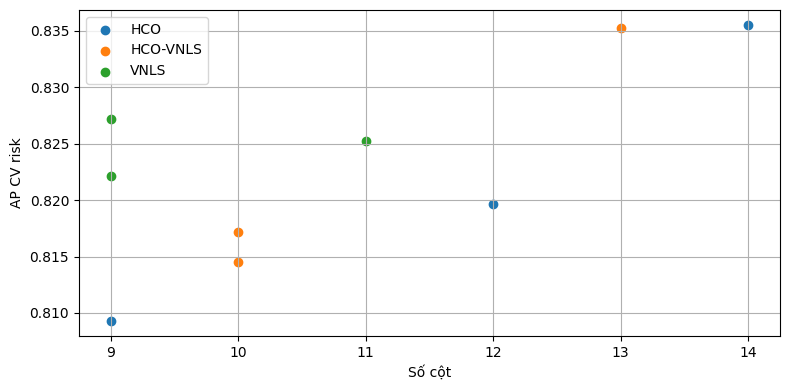

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / 'clht_code').exists() and (ROOT.parent / 'clht_code').exists():
    ROOT = ROOT.parent
sys.path.insert(0,str(ROOT))
DATA=ROOT/'data'
OUT=ROOT/'ket_qua'
OUT.mkdir(exist_ok=True)
import pandas as pd
import matplotlib.pyplot as plt
from clht_code.data import create_asof
from clht_code.models import configs,feature_columns
from clht_code.optimizers import MaskObjective,run_search,fitness
frame=create_asof(DATA,0.5,'fraction','strict'); cols=feature_columns(frame); X=frame[cols]; y=frame.risk.astype(int).to_numpy(); groups=frame.id_student.to_numpy(); cfg=[c for c in configs(41) if c.name=='HistGradientBoosting'][0]
assert fitness(0.8,5,10,1.0)==0.8 and fitness(0.8,5,10,0.0)==0.5
rows=[]
for method in ['HCO','VNLS','HCO-VNLS']:
 for seed in [41,77,123]:
  obj=MaskObjective(X,y,groups,cfg,0.85); rows.append(run_search(method,obj,seed,population=3,iterations=2))
opt=pd.DataFrame(rows); opt.to_csv(OUT/'ket_qua_hco_vnls.csv',index=False,encoding='utf-8-sig'); display(opt[['method','seed','selected_count','average_precision_cv','objective_calls','wall_seconds']])
fig,ax=plt.subplots(figsize=(8,4));
for method,g in opt.groupby('method'): ax.scatter(g.selected_count,g.average_precision_cv,label=method)
ax.set(xlabel='Số cột',ylabel='AP CV risk'); ax.legend(); ax.grid(True); fig.tight_layout(); fig.savefig(OUT/'danh_doi_bo_toi_uu.png',dpi=150); plt.show()